In [8]:
import sys

print(sys.executable)

c:\roktim_files\myfiles\work\python\nasa-prac\.venv\Scripts\python.exe


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M",
    "community": "AG",
    "longitude": 87.8682,
    "latitude": 23.2496,
    "start": "20150101",
    "end": "20251231",
    "format": "JSON"
}

In [11]:
response = requests.get(url, params=params, timeout=60)

print("Status Code:", response.status_code)

Status Code: 200


In [12]:
data = response.json()

print(data.keys())

dict_keys(['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times'])


In [13]:
print(data["properties"].keys())

print(data["properties"]["parameter"].keys())

temperature = data["properties"]["parameter"]["T2M"]

print(temperature)

dict_keys(['parameter'])
dict_keys(['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M'])
{'20150101': 20.35, '20150102': 22.81, '20150103': 23.36, '20150104': 21.2, '20150105': 18.69, '20150106': 15.77, '20150107': 15.96, '20150108': 16.32, '20150109': 15.44, '20150110': 15.15, '20150111': 14.27, '20150112': 14.46, '20150113': 15.12, '20150114': 16.32, '20150115': 17.3, '20150116': 16.76, '20150117': 16.6, '20150118': 14.67, '20150119': 14.79, '20150120': 14.61, '20150121': 15.04, '20150122': 16.46, '20150123': 17.83, '20150124': 19.29, '20150125': 19.2, '20150126': 18.94, '20150127': 20.18, '20150128': 20.78, '20150129': 20.89, '20150130': 19.22, '20150131': 15.89, '20150201': 15.85, '20150202': 17.33, '20150203': 19.12, '20150204': 20.61, '20150205': 20.61, '20150206': 19.35, '20150207': 19.13, '20150208': 19.96, '20150209': 20.1, '20150210': 21.81, '20150211': 20.2, '20150212': 20.06, '20150213': 21.65, '20150214': 21.64, '20150215': 22.32, '20150216': 23.2, '20150217': 23.29, '2015

In [14]:
climate_data = data["properties"]["parameter"]

print(climate_data.keys())

dict_keys(['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M'])


In [15]:
df = pd.DataFrame(climate_data)

df.index = pd.to_datetime(df.index, format="%Y%m%d")

df.index.name = "date"

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

              T2M  T2M_MAX  T2M_MIN  PRECTOTCORR   RH2M
date                                                   
2015-01-01  20.35    27.15    15.75         1.03  77.82
2015-01-02  22.81    29.07    18.03         8.14  78.60
2015-01-03  23.36    28.63    18.98        13.61  83.35
2015-01-04  21.20    25.47    18.39         8.28  84.07
2015-01-05  18.69    24.72    14.08         0.00  72.29
(4018, 5)
<class 'pandas.DataFrame'>
DatetimeIndex: 4018 entries, 2015-01-01 to 2025-12-31
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   T2M          4018 non-null   float64
 1   T2M_MAX      4018 non-null   float64
 2   T2M_MIN      4018 non-null   float64
 3   PRECTOTCORR  4018 non-null   float64
 4   RH2M         4018 non-null   float64
dtypes: float64(5)
memory usage: 188.3 KB
None
               T2M      T2M_MAX      T2M_MIN  PRECTOTCORR         RH2M
count  4018.000000  4018.000000  4018.000000  4018.000000  4018.000000
me

In [16]:
(df == -999).sum()

T2M            0
T2M_MAX        0
T2M_MIN        0
PRECTOTCORR    0
RH2M           0
dtype: int64

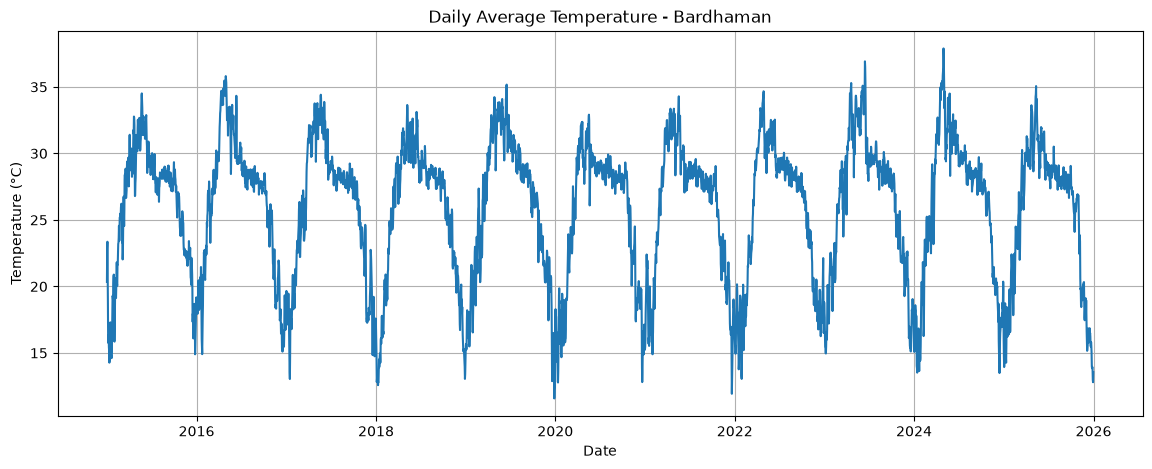

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["T2M"])

plt.title("Daily Average Temperature - Bardhaman")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid()
plt.show()

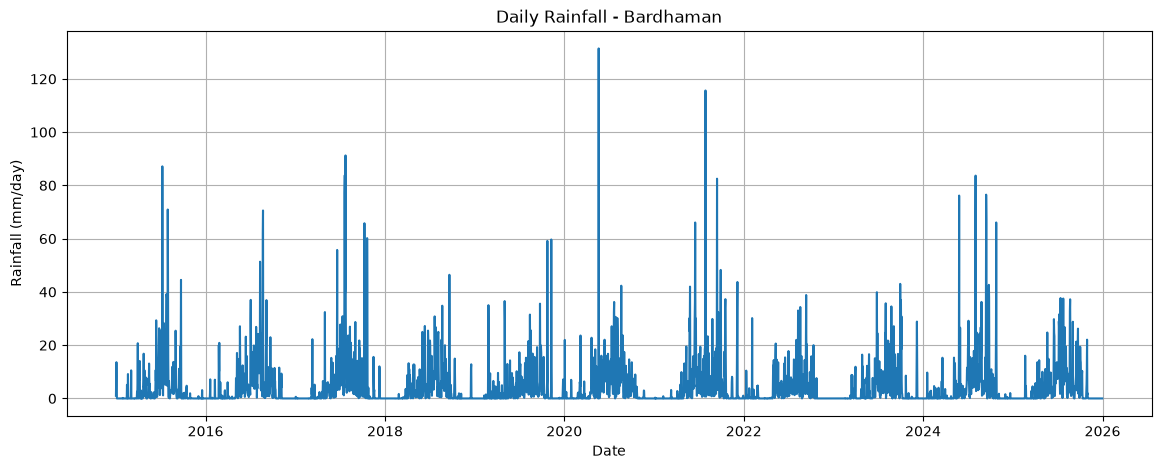

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(df.index, df["PRECTOTCORR"])

plt.title("Daily Rainfall - Bardhaman")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm/day)")

plt.grid()
plt.show()

date
2015-01-31     31.41
2015-02-28     18.68
2015-03-31     40.85
2015-04-30    109.18
2015-05-31     69.82
Freq: ME, Name: PRECTOTCORR, dtype: float64


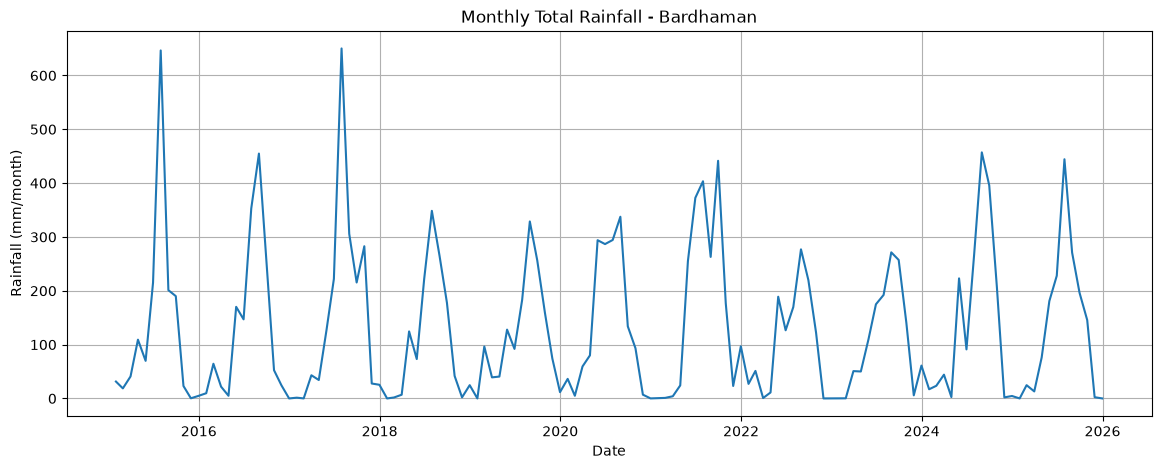

In [19]:
monthly_rainfall = df["PRECTOTCORR"].resample("ME").sum()

print(monthly_rainfall.head())

plt.figure(figsize=(14, 5))

plt.plot(monthly_rainfall.index, monthly_rainfall.values)

plt.title("Monthly Total Rainfall - Bardhaman")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm/month)")

plt.grid()
plt.show()

date
1      0.362229
2      0.922862
3      0.950587
4      1.690061
5      5.336158
6      6.600939
7     11.592141
8     10.066657
9      8.304152
10     4.234604
11     0.511697
12     0.672111
Name: PRECTOTCORR, dtype: float64


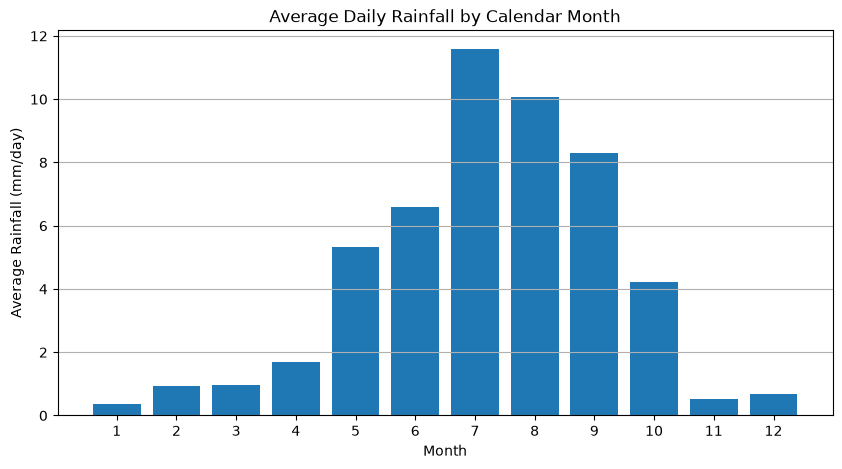

In [20]:
# monthly climatology
monthly_avg = df.groupby(df.index.month)["PRECTOTCORR"].mean()

print(monthly_avg)

plt.figure(figsize=(10, 5))

plt.bar(monthly_avg.index, monthly_avg.values)

plt.title("Average Daily Rainfall by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm/day)")

plt.xticks(range(1, 13))
plt.grid(axis="y")
plt.show()

date
2015    1252.87
2016    1210.95
2017    1393.48
2018    1013.19
2019     860.46
2020    1052.66
2021    1480.57
2022     793.16
2023     895.93
2024    1211.47
2025    1139.59
Name: PRECTOTCORR, dtype: float64


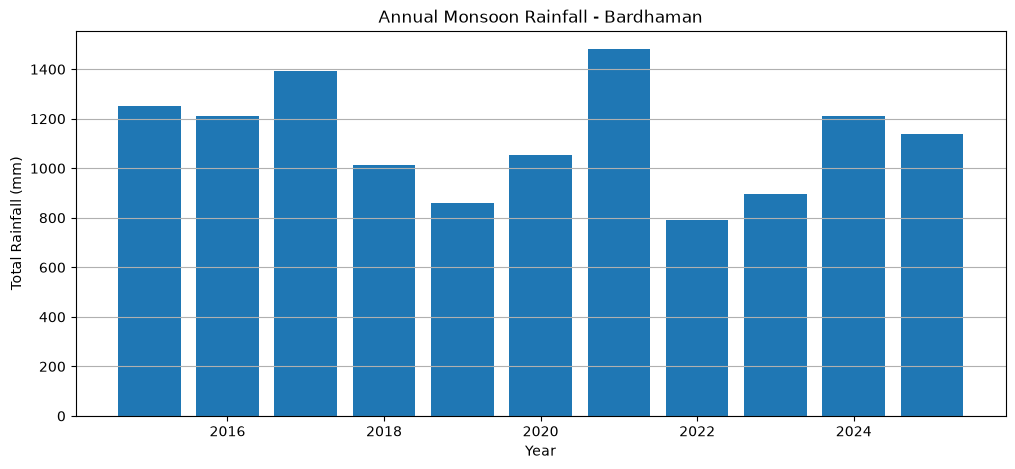

In [21]:
monsoon_data = df[df.index.month.isin([6, 7, 8, 9])]

monsoon_yearly = monsoon_data.groupby(
    monsoon_data.index.year
)["PRECTOTCORR"].sum()

print(monsoon_yearly)

plt.figure(figsize=(12, 5))

plt.bar(monsoon_yearly.index, monsoon_yearly.values)

plt.title("Annual Monsoon Rainfall - Bardhaman")
plt.xlabel("Year")
plt.ylabel("Total Rainfall (mm)")

plt.grid(axis="y")
plt.show()

In [22]:
df.index.duplicated().sum()

np.int64(0)

In [23]:
(df["T2M_MIN"] > df["T2M_MAX"]).sum()



np.int64(0)

In [24]:
(
    (df["T2M"] < df["T2M_MIN"]) |
    (df["T2M"] > df["T2M_MAX"])
).sum()

np.int64(0)

In [25]:
(df["PRECTOTCORR"] < 0).sum()



np.int64(0)

In [26]:
(
    (df["RH2M"] < 0) |
    (df["RH2M"] > 100)
).sum()

np.int64(0)

feature engineering

In [27]:
monsoon_data = df[df.index.month.isin([6, 7, 8, 9])].copy()

print(monsoon_data.head())
print(monsoon_data.shape)

              T2M  T2M_MAX  T2M_MIN  PRECTOTCORR   RH2M
date                                                   
2015-06-01  31.40    36.83    28.02         0.28  69.44
2015-06-02  32.10    38.39    27.14         0.17  63.71
2015-06-03  32.32    37.88    27.75         0.07  63.87
2015-06-04  31.74    37.48    27.08         0.61  65.81
2015-06-05  31.10    35.40    27.48         2.34  69.13
(1342, 5)


In [28]:
seasonal_features = monsoon_data.groupby(
    monsoon_data.index.year
)["PRECTOTCORR"].sum().to_frame()

seasonal_features.columns = ["total_rainfall"]

seasonal_features.index.name = "year"

print(seasonal_features)

      total_rainfall
year                
2015         1252.87
2016         1210.95
2017         1393.48
2018         1013.19
2019          860.46
2020         1052.66
2021         1480.57
2022          793.16
2023          895.93
2024         1211.47
2025         1139.59


In [29]:
avg_temp = monsoon_data.groupby(
    monsoon_data.index.year
)["T2M"].mean()

seasonal_features["avg_temperature"] = avg_temp

print(seasonal_features)

      total_rainfall  avg_temperature
year                                 
2015         1252.87        28.809918
2016         1210.95        28.694918
2017         1393.48        28.743525
2018         1013.19        28.889754
2019          860.46        29.715000
2020         1052.66        28.628279
2021         1480.57        28.271803
2022          793.16        28.894508
2023          895.93        29.902213
2024         1211.47        29.352459
2025         1139.59        28.684836


# 1. Rainfall variability

In [30]:
rainfall_std = monsoon_data.groupby(
    monsoon_data.index.year
)["PRECTOTCORR"].std()

seasonal_features["rainfall_std"] = rainfall_std

print(seasonal_features)

      total_rainfall  avg_temperature  rainfall_std
year                                               
2015         1252.87        28.809918     13.830563
2016         1210.95        28.694918     11.681424
2017         1393.48        28.743525     15.047331
2018         1013.19        28.889754      8.630582
2019          860.46        29.715000      7.177413
2020         1052.66        28.628279      8.131797
2021         1480.57        28.271803     15.644407
2022          793.16        28.894508      7.065232
2023          895.93        29.902213      8.398623
2024         1211.47        29.352459     14.467818
2025         1139.59        28.684836      9.236731


# 2. Maximum daily rainfall

In [31]:
max_rainfall = monsoon_data.groupby(
    monsoon_data.index.year
)["PRECTOTCORR"].max()

seasonal_features["max_daily_rainfall"] = max_rainfall

print(seasonal_features)

      total_rainfall  avg_temperature  rainfall_std  max_daily_rainfall
year                                                                   
2015         1252.87        28.809918     13.830563               87.15
2016         1210.95        28.694918     11.681424               70.58
2017         1393.48        28.743525     15.047331               91.25
2018         1013.19        28.889754      8.630582               46.43
2019          860.46        29.715000      7.177413               35.59
2020         1052.66        28.628279      8.131797               42.33
2021         1480.57        28.271803     15.644407              115.64
2022          793.16        28.894508      7.065232               38.84
2023          895.93        29.902213      8.398623               43.02
2024         1211.47        29.352459     14.467818               83.67
2025         1139.59        28.684836      9.236731               37.70


# 3. Number of rainy days (rainfall >= 2.5 mm)

In [32]:
rainy_days = monsoon_data.groupby(
    monsoon_data.index.year
)["PRECTOTCORR"].apply(lambda x: (x >= 2.5).sum())

seasonal_features["rainy_days"] = rainy_days

print(seasonal_features)

      total_rainfall  avg_temperature  rainfall_std  max_daily_rainfall  \
year                                                                      
2015         1252.87        28.809918     13.830563               87.15   
2016         1210.95        28.694918     11.681424               70.58   
2017         1393.48        28.743525     15.047331               91.25   
2018         1013.19        28.889754      8.630582               46.43   
2019          860.46        29.715000      7.177413               35.59   
2020         1052.66        28.628279      8.131797               42.33   
2021         1480.57        28.271803     15.644407              115.64   
2022          793.16        28.894508      7.065232               38.84   
2023          895.93        29.902213      8.398623               43.02   
2024         1211.47        29.352459     14.467818               83.67   
2025         1139.59        28.684836      9.236731               37.70   

      rainy_days  
year 

# 4. Average maximum temperature

In [33]:

avg_max_temp = monsoon_data.groupby(
    monsoon_data.index.year
)["T2M_MAX"].mean()

seasonal_features["avg_max_temperature"] = avg_max_temp


print(seasonal_features)

      total_rainfall  avg_temperature  rainfall_std  max_daily_rainfall  \
year                                                                      
2015         1252.87        28.809918     13.830563               87.15   
2016         1210.95        28.694918     11.681424               70.58   
2017         1393.48        28.743525     15.047331               91.25   
2018         1013.19        28.889754      8.630582               46.43   
2019          860.46        29.715000      7.177413               35.59   
2020         1052.66        28.628279      8.131797               42.33   
2021         1480.57        28.271803     15.644407              115.64   
2022          793.16        28.894508      7.065232               38.84   
2023          895.93        29.902213      8.398623               43.02   
2024         1211.47        29.352459     14.467818               83.67   
2025         1139.59        28.684836      9.236731               37.70   

      rainy_days  avg_ma

In [34]:
# Display the complete feature dataset
display(seasonal_features)

# Check missing values
print("Missing values:")
print(seasonal_features.isnull().sum())

# Check duplicate years
print("Duplicate years:", seasonal_features.index.duplicated().sum())

# Get statistical summary
display(seasonal_features.describe())

,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature
year,,,,,,
2015,1252.87,28.809918,13.830563,87.15,79,32.261557
2016,1210.95,28.694918,11.681424,70.58,96,32.286311
2017,1393.48,28.743525,15.047331,91.25,94,31.990902
2018,1013.19,28.889754,8.630582,46.43,92,32.429918
2019,860.46,29.715000,7.177413,35.59,81,33.725410
2020,1052.66,28.628279,8.131797,42.33,90,31.736311
2021,1480.57,28.271803,15.644407,115.64,98,31.246311
2022,793.16,28.894508,7.065232,38.84,86,32.579180
2023,895.93,29.902213,8.398623,43.02,83,33.852295


Missing values:
total_rainfall         0
avg_temperature        0
rainfall_std           0
max_daily_rainfall     0
rainy_days             0
avg_max_temperature    0
dtype: int64
Duplicate years: 0


,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature
count,11.000000,11.000000,11.000000,11.000000,11.000000,11.000000
mean,1118.575455,28.962474,10.846538,62.927273,88.636364,32.462176
std,219.041639,0.491934,3.346732,27.772324,6.185026,0.791643
min,793.160000,28.271803,7.065232,35.590000,79.000000,31.246311
25%,954.560000,28.689877,8.265210,40.585000,84.500000,32.009098
50%,1139.590000,28.809918,9.236731,46.430000,90.000000,32.286311
75%,1232.170000,29.123484,14.149191,85.410000,93.000000,32.763811
max,1480.570000,29.902213,15.644407,115.640000,98.000000,33.852295


In [35]:
from sklearn.preprocessing import StandardScaler

# features scaling

In [36]:
# Create the scaler
scaler = StandardScaler()

# Scale all six features
scaled_features = scaler.fit_transform(seasonal_features)

# Convert the result back into a DataFrame
scaled_features = pd.DataFrame(
    scaled_features,
    columns=seasonal_features.columns,
    index=seasonal_features.index
)

# Display the scaled dataset
display(scaled_features)

,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature
year,,,,,,
2015,0.643025,-0.325251,0.935143,0.914760,-1.634060,-0.265790
2016,0.442305,-0.570432,0.261639,0.289002,1.248668,-0.232994
2017,1.316290,-0.466802,1.316457,1.069595,0.909524,-0.624368
2018,-0.504604,-0.155039,-0.694443,-0.623012,0.570379,-0.042737
2019,-1.235901,1.604393,-1.149842,-1.032379,-1.294915,1.673597
2020,-0.315614,-0.712507,-0.850754,-0.777846,0.231235,-0.961663
2021,1.733292,-1.472516,1.503571,1.990672,1.587813,-1.610840
2022,-1.558145,-0.144904,-1.184997,-0.909645,-0.447054,0.155014
2023,-1.066065,2.003533,-0.767135,-0.751789,-0.955771,1.841702


In [37]:
from pathlib import Path
import joblib

# Find the ML models directory
cwd = Path.cwd()
model_dir = None

for folder in [cwd, *cwd.parents]:

    if (folder / "backend" / "ml" / "models").is_dir():
        model_dir = folder / "backend" / "ml" / "models"
        break

    if folder.name == "ml" and (folder / "models").is_dir():
        model_dir = folder / "models"
        break

if model_dir is None:
    raise FileNotFoundError("ML models folder not found!")

# Save the scaler
joblib.dump(scaler, model_dir / "feature_scaler.pkl")

print("Scaler saved successfully at:", model_dir)

Scaler saved successfully at: c:\roktim_files\myfiles\work\python\nasa-prac\backend\ml\models


In [38]:
from pathlib import Path

model_path = Path("../models/feature_scaler.pkl")

print("File exists:", model_path.exists())

File exists: True


# KMeans Clustering

## Finding the value of K

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [40]:
inertia_values = []
silhouette_values = []

# Test different numbers of clusters
k_values = range(2, 6)

for k in k_values:

    # Create the KMeans model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Train the model
    labels = kmeans.fit_predict(scaled_features)

    # Store inertia
    inertia_values.append(kmeans.inertia_)

    # Store silhouette score
    silhouette_values.append(
        silhouette_score(scaled_features, labels)
    )

print("Inertia:", inertia_values)
print("Silhouette Scores:", silhouette_values)

Inertia: [35.1477957085951, 20.06068404491213, 10.571046647222, 6.8872034562655955]
Silhouette Scores: [0.33467450273370525, 0.41732984992967187, 0.46924804455784075, 0.39448208892008413]


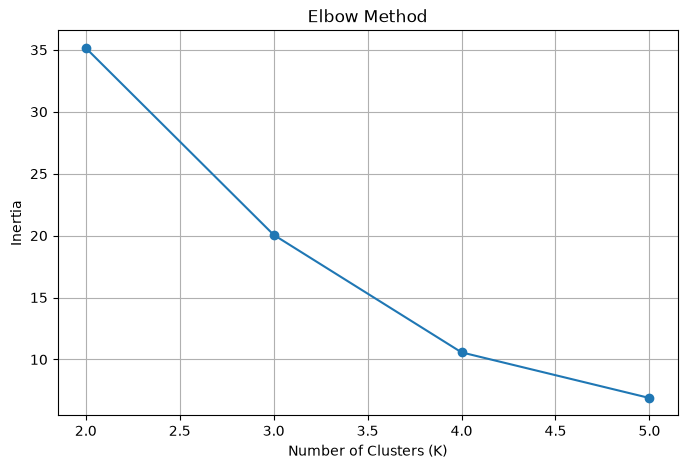

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.grid(True)
plt.show()

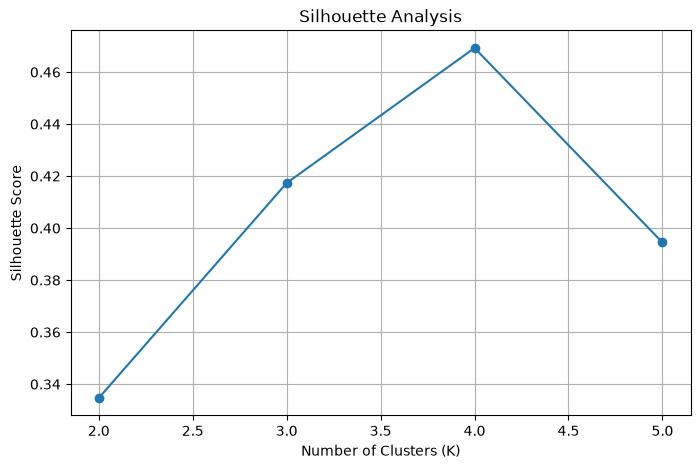

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.grid(True)
plt.show()

In [43]:
from sklearn.cluster import KMeans

# Create the K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
cluster_labels = kmeans.fit_predict(scaled_features)

# Add cluster labels to the original dataset
seasonal_features["cluster"] = cluster_labels

# Display the results
display(seasonal_features)

,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature,cluster
year,,,,,,,
2015,1252.87,28.809918,13.830563,87.15,79,32.261557,0
2016,1210.95,28.694918,11.681424,70.58,96,32.286311,3
2017,1393.48,28.743525,15.047331,91.25,94,31.990902,3
2018,1013.19,28.889754,8.630582,46.43,92,32.429918,1
2019,860.46,29.715000,7.177413,35.59,81,33.725410,2
2020,1052.66,28.628279,8.131797,42.33,90,31.736311,1
2021,1480.57,28.271803,15.644407,115.64,98,31.246311,3
2022,793.16,28.894508,7.065232,38.84,86,32.579180,1
2023,895.93,29.902213,8.398623,43.02,83,33.852295,2


In [44]:
# Calculate average climate characteristics for each cluster
cluster_profiles = seasonal_features.groupby("cluster").mean()

display(cluster_profiles)

,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature
cluster,,,,,,
0,1232.170000,29.081189,14.149191,85.410,82.5,32.605000
1,999.650000,28.774344,8.266086,41.325,89.5,32.193176
2,878.195000,29.808607,7.788018,39.305,82.0,33.788852
3,1361.666667,28.570082,14.124388,92.490,96.0,31.841175


In [45]:
import joblib

joblib.dump(kmeans, model_dir / "kmeans_model.pkl")

print("K-Means model saved successfully!")

K-Means model saved successfully!


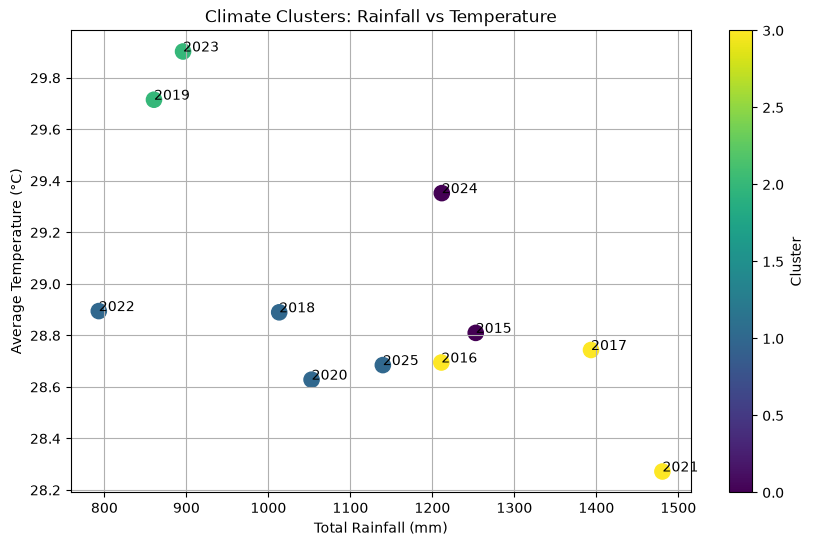

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    seasonal_features["total_rainfall"],
    seasonal_features["avg_temperature"],
    c=seasonal_features["cluster"],
    cmap="viridis",
    s=120
)

for year in seasonal_features.index:
    plt.annotate(
        str(year),
        (
            seasonal_features.loc[year, "total_rainfall"],
            seasonal_features.loc[year, "avg_temperature"]
        )
    )

plt.xlabel("Total Rainfall (mm)")
plt.ylabel("Average Temperature (°C)")
plt.title("Climate Clusters: Rainfall vs Temperature")
plt.colorbar(label="Cluster")
plt.grid(True)

plt.show()

In [47]:
# Save processed data

processed_dir = Path("../data/processed")

processed_dir.mkdir(parents=True, exist_ok=True)

cluster_profiles.to_csv(
    processed_dir / "cluster_profiles.csv"
)

seasonal_features.to_csv(
    processed_dir / "yearly_cluster_results.csv"
)

print("Cluster results saved successfully!")

Cluster results saved successfully!


In [48]:
from pathlib import Path

processed_dir = Path("../data/processed")
model_dir = Path("../models")

print("Processed data folder exists:", processed_dir.exists())
print("Models folder exists:", model_dir.exists())

print("\nProcessed files:")
for file in processed_dir.iterdir():
    print(file.name)

print("\nModel files:")
for file in model_dir.iterdir():
    print(file.name)

Processed data folder exists: True
Models folder exists: True

Processed files:
climate_anomaly_results.csv
cluster_profiles.csv
yearly_cluster_results.csv

Model files:
feature_scaler.pkl
isolation_forest_model.pkl
kmeans_model.pkl


In [49]:
# from ml.pipeline.clustering import predict_climate_cluster

# predictions = predict_climate_cluster(seasonal_features)

# print(predictions)

## Isolation Forest – Climate Anomaly Detection

In [50]:
import pandas as pd
import numpy as np

# Select the climate features
feature_columns = [
    "total_rainfall",
    "avg_temperature",
    "rainfall_std",
    "max_daily_rainfall",
    "rainy_days",
    "avg_max_temperature"
]

# Create the dataset for anomaly detection
X = seasonal_features[feature_columns].copy()

print(X.head())

      total_rainfall  avg_temperature  rainfall_std  max_daily_rainfall  \
year                                                                      
2015         1252.87        28.809918     13.830563               87.15   
2016         1210.95        28.694918     11.681424               70.58   
2017         1393.48        28.743525     15.047331               91.25   
2018         1013.19        28.889754      8.630582               46.43   
2019          860.46        29.715000      7.177413               35.59   

      rainy_days  avg_max_temperature  
year                                   
2015          79            32.261557  
2016          96            32.286311  
2017          94            31.990902  
2018          92            32.429918  
2019          81            33.725410  


In [51]:
from sklearn.ensemble import IsolationForest

# Create the model
isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42
)

# Train the model
isolation_model.fit(X)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [52]:
# Predict anomalies
predictions = isolation_model.predict(X)

# Calculate anomaly scores
anomaly_scores = -isolation_model.score_samples(X)

# Store results
anomaly_results = seasonal_features.copy()

anomaly_results["anomaly"] = predictions
anomaly_results["anomaly_score"] = anomaly_scores

display(anomaly_results)

,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature,cluster,anomaly,anomaly_score
year,,,,,,,,,
2015,1252.87,28.809918,13.830563,87.15,79,32.261557,0,1,0.488349
2016,1210.95,28.694918,11.681424,70.58,96,32.286311,3,1,0.472836
2017,1393.48,28.743525,15.047331,91.25,94,31.990902,3,1,0.479775
2018,1013.19,28.889754,8.630582,46.43,92,32.429918,1,1,0.449726
2019,860.46,29.715000,7.177413,35.59,81,33.725410,2,-1,0.535417
2020,1052.66,28.628279,8.131797,42.33,90,31.736311,1,1,0.457143
2021,1480.57,28.271803,15.644407,115.64,98,31.246311,3,-1,0.616605
2022,793.16,28.894508,7.065232,38.84,86,32.579180,1,1,0.484353
2023,895.93,29.902213,8.398623,43.02,83,33.852295,2,-1,0.529725


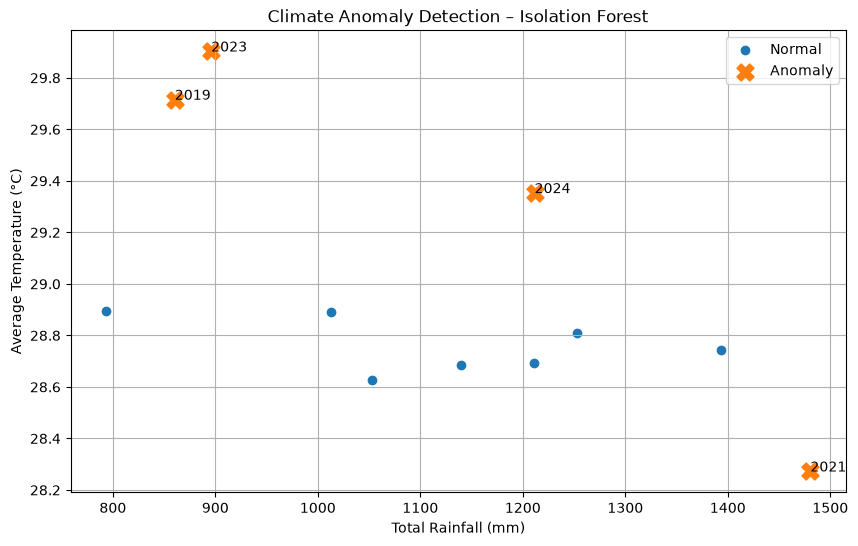

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

normal = anomaly_results["anomaly"] == 1
anomalous = anomaly_results["anomaly"] == -1

plt.scatter(
    anomaly_results.loc[normal, "total_rainfall"],
    anomaly_results.loc[normal, "avg_temperature"],
    label="Normal",
    marker="o"
)

plt.scatter(
    anomaly_results.loc[anomalous, "total_rainfall"],
    anomaly_results.loc[anomalous, "avg_temperature"],
    label="Anomaly",
    marker="X",
    s=150
)

for year, row in anomaly_results.iterrows():
    if row["anomaly"] == -1:
        plt.annotate(str(year), (
            row["total_rainfall"],
            row["avg_temperature"]
        ))

plt.xlabel("Total Rainfall (mm)")
plt.ylabel("Average Temperature (°C)")
plt.title("Climate Anomaly Detection – Isolation Forest")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
import joblib
from pathlib import Path

# Locate the ML folders
model_dir = Path("../models")
processed_dir = Path("../data/processed")

# Save trained model
joblib.dump(
    isolation_model,
    model_dir / "isolation_forest_model.pkl"
)

# Save anomaly results
anomaly_results.to_csv(
    processed_dir / "climate_anomaly_results.csv"
)

print("Isolation Forest model and results saved successfully!")

Isolation Forest model and results saved successfully!


In [55]:

from pathlib import Path
import sys

# Add the backend directory to Python's import path
backend_dir = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(backend_dir))

# Import our new function
from ml.pipeline.anomaly_detection import detect_climate_anomalies

# Select the climate features
feature_columns = [
    "total_rainfall",
    "avg_temperature",
    "rainfall_std",
    "max_daily_rainfall",
    "rainy_days",
    "avg_max_temperature"
]

# Run anomaly detection
isolation_model, anomaly_results = detect_climate_anomalies(
    seasonal_features,
    feature_columns
)

# Display results
display(anomaly_results)


,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature,cluster,anomaly,anomaly_score
year,,,,,,,,,
2015,1252.87,28.809918,13.830563,87.15,79,32.261557,0,1,0.488349
2016,1210.95,28.694918,11.681424,70.58,96,32.286311,3,1,0.472836
2017,1393.48,28.743525,15.047331,91.25,94,31.990902,3,1,0.479775
2018,1013.19,28.889754,8.630582,46.43,92,32.429918,1,1,0.449726
2019,860.46,29.715000,7.177413,35.59,81,33.725410,2,-1,0.535417
2020,1052.66,28.628279,8.131797,42.33,90,31.736311,1,1,0.457143
2021,1480.57,28.271803,15.644407,115.64,98,31.246311,3,-1,0.616605
2022,793.16,28.894508,7.065232,38.84,86,32.579180,1,1,0.484353
2023,895.93,29.902213,8.398623,43.02,83,33.852295,2,-1,0.529725


In [56]:
import os
import sys

print("Current working directory:")
print(os.getcwd())

print("\nPython search paths:")
for path in sys.path:
    print(path)

Current working directory:
c:\roktim_files\myfiles\work\python\nasa-prac\backend\ml\notebooks

Python search paths:
C:\roktim_files\myfiles\work\python\nasa-prac\backend
c:\roktim_files\myfiles\work\python\nasa-prac\backend
C:\Users\rokti\AppData\Roaming\uv\python\cpython-3.13-windows-x86_64-none\python313.zip
C:\Users\rokti\AppData\Roaming\uv\python\cpython-3.13-windows-x86_64-none\DLLs
C:\Users\rokti\AppData\Roaming\uv\python\cpython-3.13-windows-x86_64-none\Lib
C:\Users\rokti\AppData\Roaming\uv\python\cpython-3.13-windows-x86_64-none
c:\roktim_files\myfiles\work\python\nasa-prac\.venv

c:\roktim_files\myfiles\work\python\nasa-prac\.venv\Lib\site-packages
C:\roktim_files\myfiles\work\python\nasa-prac\src


In [57]:
from pathlib import Path
import sys

# Find the project root directory
current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "backend" / "ml" / "pipeline" / "clustering.py").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not locate the backend folder.")

# Add backend to Python's module search path
backend_path = project_root / "backend"

if str(backend_path) not in sys.path:
    sys.path.insert(0, str(backend_path))

print("Backend path added:", backend_path)

Backend path added: c:\roktim_files\myfiles\work\python\nasa-prac\backend


In [58]:
import importlib
import ml.pipeline.clustering as clustering

importlib.reload(clustering)

train_climate_clusters = clustering.train_climate_clusters
predict_climate_cluster = clustering.predict_climate_cluster

clustered_data = train_climate_clusters(
    seasonal_features,
    n_clusters=4
)

predictions = predict_climate_cluster(seasonal_features)

print(predictions)

display(clustered_data)

[0 3 3 1 2 1 3 1 2 0 1]


,total_rainfall,avg_temperature,rainfall_std,max_daily_rainfall,rainy_days,avg_max_temperature,cluster
year,,,,,,,
2015,1252.87,28.809918,13.830563,87.15,79,32.261557,0
2016,1210.95,28.694918,11.681424,70.58,96,32.286311,3
2017,1393.48,28.743525,15.047331,91.25,94,31.990902,3
2018,1013.19,28.889754,8.630582,46.43,92,32.429918,1
2019,860.46,29.715000,7.177413,35.59,81,33.725410,2
2020,1052.66,28.628279,8.131797,42.33,90,31.736311,1
2021,1480.57,28.271803,15.644407,115.64,98,31.246311,3
2022,793.16,28.894508,7.065232,38.84,86,32.579180,1
2023,895.93,29.902213,8.398623,43.02,83,33.852295,2


In [60]:
from pathlib import Path

model_dir = Path.cwd().parent / "models"

print("Model directory:", model_dir)
print("Directory exists:", model_dir.exists())

for file in model_dir.iterdir():
    print(file.name)

Model directory: c:\roktim_files\myfiles\work\python\nasa-prac\backend\ml\models
Directory exists: True
feature_scaler.pkl
isolation_forest_model.pkl
kmeans_model.pkl
